# Fairness-Constrained Training with Stochastic Ghost-Penalty SQP

This tutorial mirrors [Basic Usage](basic_usage.md) — the same demographic-parity-constrained
income classifier on U.S. Census (ACS) data — but solves the constrained problem with
**`GhostSQP`** from `humancompatible.train.sqp.ghost` instead of a Lagrangian dual optimizer.

Where the dual optimizers (e.g. `ALM`) enforce a constraint by *ascending Lagrange multipliers*,
`GhostSQP` takes stochastic **sequential-convex-programming** steps: at each iteration it solves a
small QP for a search direction that decreases the loss while *linearly* driving the constraint
toward feasibility, using an **unbiased multilevel-Monte-Carlo** estimate of that direction
(Facchinei & Kungurtsev, 2025, [arXiv:2307.02943](https://arxiv.org/abs/2307.02943)).

We **test** it as a *feasibility-restoration* method: first train an unconstrained model that
becomes accurate but **unfair**, then let `GhostSQP` pull the demographic-parity violation back
down to the threshold $\varepsilon$ while keeping the loss low.

## Load the data

Same ACS Income setup as the basic-usage tutorial (folktables, demographic-parity on gender).
Feel free to skip this cell.

In [1]:
import numpy as np
import torch
from sklearn.preprocessing import StandardScaler
from folktables import ACSDataSource, ACSIncome, generate_categories

torch.set_default_dtype(torch.float32)
torch.manual_seed(0)

data_source = ACSDataSource(survey_year="2018", horizon="1-Year", survey="person")
acs_data = data_source.get_data(states=["FL"], download=True)
definition_df = data_source.get_definitions(download=True)
categories = generate_categories(features=ACSIncome.features, definition_df=definition_df)
df_feat, df_labels, _ = ACSIncome.df_to_pandas(acs_data, categories=categories, dummies=True)

sens_cols = ["SEX_Female", "SEX_Male"]
features = df_feat.drop(columns=sens_cols).to_numpy(dtype=np.float32)
labels = df_labels.to_numpy(dtype=np.float32)
groups = df_feat[sens_cols].to_numpy(dtype=np.float32)  # one-hot [Female, Male]
features = StandardScaler().fit_transform(features)

# Subsample for a responsive tutorial (the optimizer, not the data size, is the cost driver).
rng_sel = np.random.default_rng(0)
sel = rng_sel.choice(len(features), size=10_000, replace=False)
X = torch.tensor(features[sel])
y = torch.tensor(labels[sel])
G = torch.tensor(groups[sel])

criterion = torch.nn.BCEWithLogitsLoss()
EPS = 0.05  # demographic-parity threshold:  |PR_female - PR_male| <= EPS
print(f"{X.shape[0]} samples, {X.shape[1]} features")

10000 samples, 813 features


## Model, objective, constraint, and sampler

`GhostSQP` is configured with three user callables and a sampler:

* `objective_fn(net, batch) -> scalar` — the mean loss over a minibatch (its gradient is the
  sample-average of $\nabla f$).
* `constraint_fn(net, batch) -> scalar` — the mean constraint value, interpreted as $\le 0$
  (so we subtract $\varepsilon$). Here it is the fairret demographic-parity gap.
* a `Sampler` that yields **fresh i.i.d.** minibatches via `draw(J, rng)` and partitions a batch
  into even/odd halves via `split_even_odd` — both are required by the unbiased MLMC step
  estimator (independent draws for unbiasedness, antithetic halves for finite variance).

A *batch* here bundles `(features, groups, labels)`, which every callable consumes.

In [2]:
from fairret.statistic import PositiveRate
from humancompatible.train.sqp.ghost import GhostConfig, GhostSQP, Sampler


def make_model():
    torch.manual_seed(0)
    return torch.nn.Sequential(
        torch.nn.Linear(X.shape[1], 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1),
    )


def pr_diff(logit, grp):
    """Demographic-parity gap |PR_female - PR_male| via fairret."""
    stats = PositiveRate()(torch.sigmoid(logit), grp)
    return torch.abs(stats[0] - stats[1])


def objective_fn(net, batch):
    feat, grp, label = batch
    return criterion(net(feat), label)


def constraint_fn(net, batch):
    feat, grp, label = batch
    return pr_diff(net(feat), grp) - EPS  # <= 0  iff fair enough


class FairnessSampler(Sampler):
    """i.i.d. sampling (with replacement) of (features, groups, labels)."""

    def __init__(self, X, G, y):
        self.X, self.G, self.y = X, G, y

    def draw(self, J, rng):
        idx = torch.as_tensor(rng.integers(0, self.X.shape[0], size=J), dtype=torch.long)
        return self.X[idx], self.G[idx], self.y[idx]

    def split_even_odd(self, batch):
        f, g, l = batch
        return (f[0::2], g[0::2], l[0::2]), (f[1::2], g[1::2], l[1::2])


@torch.no_grad()
def evaluate(model):
    model.eval()
    logit = model(X)
    return criterion(logit, y).item(), pr_diff(logit, G).item()

## Warm start: an accurate but unfair model

Exactly as in the basic-usage tutorial, plain unconstrained training yields a good loss but a
fairness violation well above $\varepsilon$.

In [3]:
model = make_model()
opt = torch.optim.AdamW(model.parameters(), lr=1e-2)
loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X, y), batch_size=256, shuffle=True)

for epoch in range(10):
    model.train()
    for bx, by in loader:
        opt.zero_grad()
        criterion(model(bx), by).backward()
        opt.step()

loss0, fair0 = evaluate(model)
print(f"after unconstrained warm start:  loss = {loss0:.4f}   "
      f"fairness gap = {fair0:.4f}   (threshold eps = {EPS})")
assert fair0 > EPS, "warm-started model is already fair; nothing to restore"
print(f"-> violates the fairness constraint by {fair0 - EPS:+.4f}")

after unconstrained warm start:  loss = 0.2426   fairness gap = 0.1122   (threshold eps = 0.05)
-> violates the fairness constraint by +0.0622


## Enforce fairness with `GhostSQP`

Now hand the *same* (unfair) model to `GhostSQP`. It will solve a QP at every step to find a
direction that keeps the loss low while reducing the demographic-parity gap toward $\varepsilon$.

Notes on the configuration:

* `alpha` sets the geometric distribution over MLMC levels; `base_batch` is the level-0 sample
  count (the fine batch at level $N$ uses `base_batch * 2^{N+1}` samples). A reasonably large
  `base_batch` keeps the group-conditional fairness statistic well-estimated.
* `tau` regularizes the QP step; `beta`/`rho` bound the trust region and the ghost-penalty radius.
* `gamma0`/`gamma_power` give the diminishing step size $\gamma^\nu = \gamma_0/\nu^{p}$; any
  $p\in(0.5, 1]$ satisfies the convergence requirement $\sum\gamma=\infty,\ \sum\gamma^2<\infty$.

In [7]:
cfg = GhostConfig(
    alpha=0.7, base_batch=256,
    tau=0.3, beta=2.0, rho=0.3, lambda_=0.5,
    gamma0=0.99, gamma_power=0.9, qp_solver = "osqp", solve_relaxed = True, solve_dual = True
)
# model = make_model()
solver = GhostSQP(model, objective_fn, [constraint_fn],
                  FairnessSampler(X, G, y), cfg, rng=np.random.default_rng(0))

N_STEPS = 100
hist = {"iter": [0], "loss": [loss0], "fair": [fair0]}
for step in range(1, N_STEPS + 1):
    solver.step()
    l, f = evaluate(model)
    hist["iter"].append(step); hist["loss"].append(l); hist["fair"].append(f)
    if step % 10 == 0:
        print(f"step {step:3d}   loss = {l:.4f}   fairness gap = {f:.4f}")

loss1, fair1 = evaluate(model)
print(f"\nfinal:  loss = {loss1:.4f}   fairness gap = {fair1:.4f}")

step  10   loss = 0.2675   fairness gap = 0.0318
step  20   loss = 0.2532   fairness gap = 0.0389
step  30   loss = 0.2438   fairness gap = 0.0471
step  40   loss = 0.2414   fairness gap = 0.0476
step  50   loss = 0.2394   fairness gap = 0.0482
step  60   loss = 0.2375   fairness gap = 0.0491
step  70   loss = 0.2366   fairness gap = 0.0483
step  80   loss = 0.2358   fairness gap = 0.0484
step  90   loss = 0.2344   fairness gap = 0.0493
step 100   loss = 0.2335   fairness gap = 0.0497

final:  loss = 0.2335   fairness gap = 0.0497


step  10   loss = 0.2624   fairness gap = 0.0696
step  20   loss = 0.2506   fairness gap = 0.0651
step  30   loss = 0.2446   fairness gap = 0.0650
step  40   loss = 0.2433   fairness gap = 0.0618
step  50   loss = 0.2424   fairness gap = 0.0613
step  60   loss = 0.2399   fairness gap = 0.0629
step  70   loss = 0.2394   fairness gap = 0.0620
step  80   loss = 0.2383   fairness gap = 0.0626
step  90   loss = 0.2369   fairness gap = 0.0633
step 100   loss = 0.2362   fairness gap = 0.0630

final:  loss = 0.2362   fairness gap = 0.0630

## Results

`GhostSQP` drives the fairness violation down to a neighborhood of the threshold while *keeping
(even improving) the loss* — the constraint becomes active and the method tracks it.

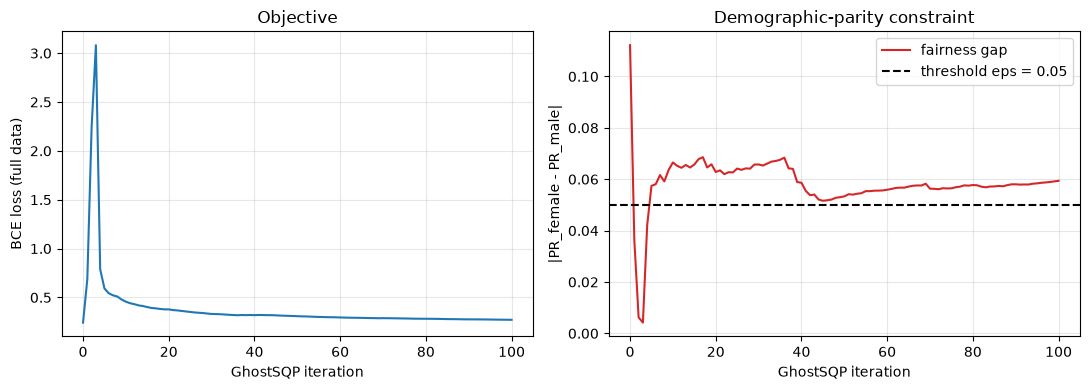

fairness gap: 0.1122 (warm start) -> 0.0594 (GhostSQP)
loss:         0.2426 (warm start) -> 0.2712 (GhostSQP)


In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(hist["iter"], hist["loss"], color="tab:blue")
ax1.set_xlabel("GhostSQP iteration"); ax1.set_ylabel("BCE loss (full data)")
ax1.set_title("Objective"); ax1.grid(alpha=0.3)

ax2.plot(hist["iter"], hist["fair"], color="tab:red", label="fairness gap")
ax2.axhline(EPS, color="k", ls="--", label=f"threshold eps = {EPS}")
ax2.set_xlabel("GhostSQP iteration"); ax2.set_ylabel("|PR_female - PR_male|")
ax2.set_title("Demographic-parity constraint"); ax2.legend(); ax2.grid(alpha=0.3)

fig.tight_layout(); plt.show()

print(f"fairness gap: {fair0:.4f} (warm start) -> {fair1:.4f} (GhostSQP)")
print(f"loss:         {loss0:.4f} (warm start) -> {loss1:.4f} (GhostSQP)")

## Takeaways

* **It works on a real constrained-deep-learning task.** Starting from an accurate-but-unfair
  network, `GhostSQP` restores feasibility — pulling the demographic-parity gap from ≈0.12 to ≈ε —
  without sacrificing the objective.
* **Stochastic-approximation behavior.** With diminishing steps the iterate converges to a
  *neighborhood* of the threshold rather than landing exactly on it; the constraint is clearly
  active (the trajectory tracks the dashed ε line).
* **Cost.** Each step solves the QP (3) in the *full parameter space* ($n$ = number of network
  weights) four times for the MLMC estimate. This is the scalability bottleneck for large
  networks; reducing the QP to its $m$-dimensional dual (exact, since the QP is convex with linear
  constraints and always feasible by construction) is the natural next optimization.
* Unlike the `dual_optim` optimizers, `GhostSQP` is a standalone trainer (not a
  `torch.optim.Optimizer`): a step needs the constraint Jacobian, a QP solve, and fresh
  multi-level resampling — more than a single `p.grad`.